# Figure 3 Supplement 3: Stopping-model comparison

Each alternative changes one part of the main stopping model and is fit to the
same trials (`scripts/run_stopping_fits.py`; one fit per subject, jointly over
that subject's six OL blocks, so the comparison uses all six blocks rather than
only the low-SNR blocks 1–3 shown in the other Figure 3 supplements).

- **A — total ΔAIC** (alternative − main, summed over subjects; positive =
  main model better), log scale.
- **B — per subject:** the fraction of subjects for whom the main model is
  better by more than 2 AIC units, the two are within 2, or the alternative is
  better by more than 2.

Main model: knee-form bound time course (falls from a high start to the plateau
at a free knee step, then a slow slope) shared across a subject's blocks;
plateau, bound variability and guess, lapse and anticipation rates per block;
sensory noise and NDT ∈ {1, 2} steps shared.

Alternatives, grouped by what they test:

- **Bound time course:** constant bound (`flat`); constant bound with a guess
  rate that varies over the trial, i.e. more guessing early instead of a high
  early bound (`flat_guess_tc`); the collapse through fixed knots at steps 1, 6
  and 16 (`knots`, the previous main model); the bound flat after the knee
  (`knee_flat`); a separate time course per block (`per_block_tc`); a separate
  time course per SNR (`tc_by_snr`).
- **Sensory noise:** none (`no_noise`).
- **NDT:** up to 3 steps (`ndt123`).
- **Guess, lapse and anticipation rates:** shared across blocks (`shared_rates`).

The knots-form variant with both time courses (`both_tc`) is in
Test_stoppingModel and not shown.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label

PROCESSED = Path('../data/processed')

In [2]:
TASK = 'OL'
AIC_MARGIN = 2.0
VARIANTS = {   # file suffix: label (grouped by what the alternative tests)
    'flat': 'Constant bound',
    'flat_guess_tc': 'Constant bound + early guessing',
    'knots': 'Collapse through fixed knots',
    'knee_flat': 'Flat after the knee',
    'per_block_tc': 'Time course per block',
    'tc_by_snr': 'Time course per SNR',
    'no_noise': 'No sensory noise',
    'ndt123': 'NDT up to 3 steps',
    'shared_rates': 'Rates shared across blocks',
}
GROUP_BREAKS = ['no_noise', 'ndt123', 'shared_rates']   # a gap before each new group

def _per_subject(variant):
    f = pd.read_pickle(PROCESSED / f'stopping_fits_{variant}.pkl')
    s = f[f.task == TASK].groupby('subject_index').first()
    return pd.DataFrame({'aic': 2 * s.nll + 2 * s.n_params, 'n_params': s.n_params, 'success': s.success})

main = _per_subject('main')
rows = []
for v, label in VARIANTS.items():
    alt = _per_subject(v)
    d = (alt.aic - main.aic).dropna()
    rows.append({'variant': v, 'label': label, 'subjects': len(d), 'ΔAIC total': d.sum(), 'ΔAIC median': d.median(),
                 'Δ params / subject': int((alt.n_params - main.n_params).median()),
                 'main better': np.mean(d > AIC_MARGIN), 'within 2': np.mean(d.abs() <= AIC_MARGIN),
                 'alternative better': np.mean(d < -AIC_MARGIN),
                 'not converged (alt / main)': f'{int((~alt.success).sum())} / {int((~main.success).sum())}'})
comp = pd.DataFrame(rows).set_index('variant')
display(comp.round(3))

,label,subjects,ΔAIC total,ΔAIC median,Δ params / subject,main better,within 2,alternative better,not converged (alt / main)
variant,,,,,,,,,
flat,Constant bound,60,4628.912,67.094,-3,0.967,0.033,0.000,0 / 0
flat_guess_tc,Constant bound + early guessing,60,3802.561,49.956,-1,0.967,0.000,0.033,0 / 0
knots,Collapse through fixed knots,60,1258.889,11.388,-1,0.733,0.217,0.050,0 / 0
knee_flat,Flat after the knee,60,529.618,4.639,-1,0.633,0.283,0.083,1 / 0
per_block_tc,Time course per block,60,1154.073,21.846,15,0.950,0.033,0.017,0 / 0
tc_by_snr,Time course per SNR,60,75.753,3.517,3,0.633,0.100,0.267,0 / 0
no_noise,No sensory noise,60,1345.207,13.571,-1,0.800,0.100,0.100,0 / 0
ndt123,NDT up to 3 steps,60,316.648,6.455,1,0.600,0.217,0.183,0 / 0
shared_rates,Rates shared across blocks,60,13613.037,68.322,-15,0.733,0.050,0.217,1 / 0


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


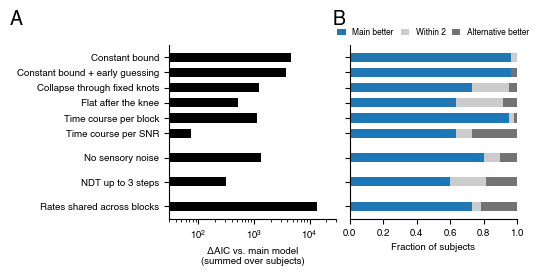

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S03.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

# y positions, top to bottom, with a gap between groups.
ypos, y = {}, 0.0
for v in VARIANTS:
    if v in GROUP_BREAKS:
        y += 0.6
    ypos[v] = y
    y += 1.0
yy = np.array([ypos[v] for v in VARIANTS])

fig = plt.figure(figsize=(13 * CM, 6.5 * CM))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.08, left=0.3, right=0.98, bottom=0.17, top=0.85)
ax_a, ax_b = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

ax_a.barh(yy, comp['ΔAIC total'], color='k', height=0.6)
ax_a.set_xscale('log')
ax_a.set_xlim(30, 3e4)
ax_a.set_yticks(yy)
ax_a.set_yticklabels(list(VARIANTS.values()))
ax_a.invert_yaxis()
ax_a.set_xlabel('ΔAIC vs. main model\n(summed over subjects)')

left = np.zeros(len(VARIANTS))
for col, color in (('main better', MODEL), ('within 2', '0.8'), ('alternative better', '0.45')):
    w = comp[col].to_numpy()
    ax_b.barh(yy, w, left=left, color=color, height=0.6, label=col.capitalize())
    left += w
ax_b.set_xlim(0, 1)
ax_b.set_yticks(yy)
ax_b.set_yticklabels([])
ax_b.invert_yaxis()
ax_b.set_xlabel('Fraction of subjects')
ax_b.legend(fontsize=6, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3,
            handlelength=1, columnspacing=0.8)

for ax in (ax_a, ax_b):
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_a, 'A', dx=-0.95, dy=1.2)
add_panel_label(ax_b, 'B', dx=-0.1, dy=1.2)

out = FIGURES_DIR / 'Figure03_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)